In [9]:
import pandas as pd
import numpy as np

In [10]:
df = pd.read_csv('house_price_india_2026.csv')
print(df.head())
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df.describe())            

        City    Location  Area_sqft  Bedrooms  Bathrooms  Floor  \
0      Delhi       Noida       2520         3          2     14   
1       Pune    Hadapsar       2260         3          2     14   
2  Hyderabad  Kukatpally       2596         3          3      9   
3      Delhi       Noida       3369         5          4     14   
4  Bangalore  Whitefield       1452         3          4      6   

   Property_Age_Years  Parking       Furnished      Property_Type  Price_INR  
0                  18        1       Furnished          Apartment   26770000  
1                  10        1  Semi-Furnished              Villa   24219000  
2                  13        0       Furnished          Apartment   27905000  
3                  24        1     Unfurnished  Independent House   40765000  
4                   6        1       Furnished              Villa   20253000  
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column              No

In [11]:

df = df.drop_duplicates()

print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Fill numerical columns with median
numerical_cols = [
    "Area_sqft",
    "Bedrooms",
    "Bathrooms",
    "Floor",
    "Property_Age_Years",
    "Parking"
]

for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical columns with mode
categorical_cols = [
    "City",
    "Location",
    "Furnished",
    "Property_Type"
]

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

df = df.dropna(subset=["Price_INR"])

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape after cleaning:")
print(df.shape)


Missing values before cleaning:
City                  0
Location              0
Area_sqft             0
Bedrooms              0
Bathrooms             0
Floor                 0
Property_Age_Years    0
Parking               0
Furnished             0
Property_Type         0
Price_INR             0
dtype: int64



Missing values after cleaning:
City                  0
Location              0
Area_sqft             0
Bedrooms              0
Bathrooms             0
Floor                 0
Property_Age_Years    0
Parking               0
Furnished             0
Property_Type         0
Price_INR             0
dtype: int64

Dataset shape after cleaning:
(5000, 11)


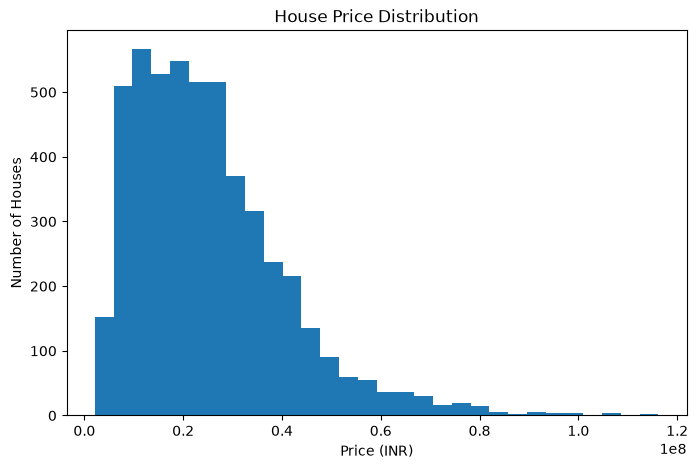

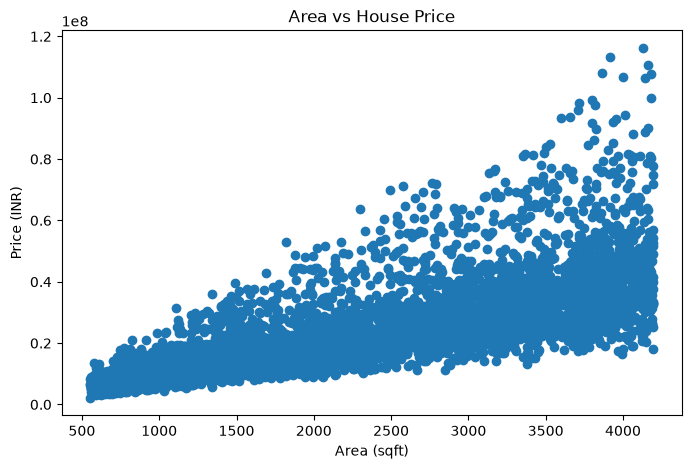

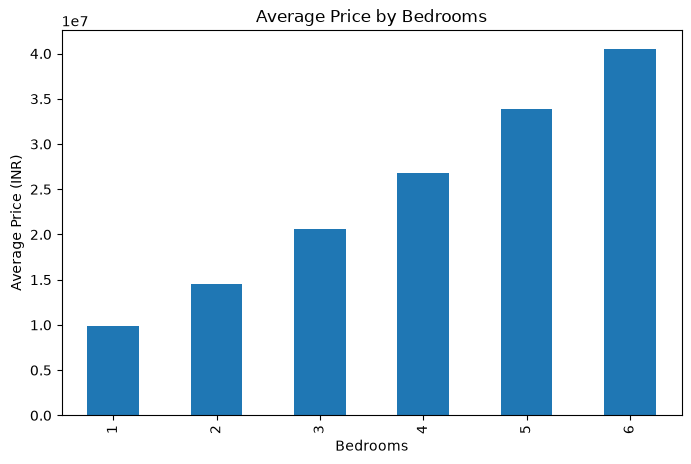

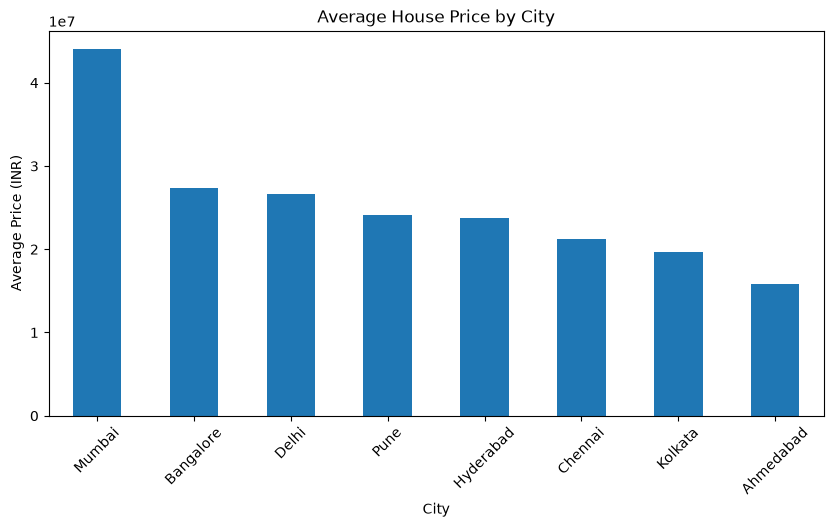

In [12]:
import matplotlib.pyplot as plt

# Price distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Price_INR"], bins=30)
plt.xlabel("Price (INR)")
plt.ylabel("Number of Houses")
plt.title("House Price Distribution")
plt.show()


# Area vs Price
plt.figure(figsize=(8, 5))
plt.scatter(df["Area_sqft"], df["Price_INR"])
plt.xlabel("Area (sqft)")
plt.ylabel("Price (INR)")
plt.title("Area vs House Price")
plt.show()


# Bedrooms vs Price
plt.figure(figsize=(8, 5))
df.groupby("Bedrooms")["Price_INR"].mean().plot(kind="bar")
plt.xlabel("Bedrooms")
plt.ylabel("Average Price (INR)")
plt.title("Average Price by Bedrooms")
plt.show()


# Average price by city
city_price = df.groupby("City")["Price_INR"].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
city_price.plot(kind="bar")
plt.xlabel("City")
plt.ylabel("Average Price (INR)")
plt.title("Average House Price by City")
plt.xticks(rotation=45)
plt.show()

In [13]:
print("\nCorrelation:")
print(df[numerical_cols + ["Price_INR"]].corr()["Price_INR"].sort_values(ascending=False))


Correlation:
Price_INR             1.000000
Area_sqft             0.728759
Bedrooms              0.673337
Bathrooms             0.596613
Floor                 0.068493
Parking               0.010061
Property_Age_Years   -0.092706
Name: Price_INR, dtype: float64


In [14]:
# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=["City", "Location", "Furnished", "Property_Type"],
    drop_first=True
)

print("\nEncoded Dataset:")
print(df_encoded.head())

print("\nNew Columns:")
print(df_encoded.columns.tolist())


Encoded Dataset:
   Area_sqft  Bedrooms  Bathrooms  Floor  Property_Age_Years  Parking  \
0       2520         3          2     14                  18        1   
1       2260         3          2     14                  10        1   
2       2596         3          3      9                  13        0   
3       3369         5          4     14                  24        1   
4       1452         3          4      6                   6        1   

   Price_INR  City_Bangalore  City_Chennai  City_Delhi  ...  Location_Thane  \
0   26770000           False         False        True  ...           False   
1   24219000           False         False       False  ...           False   
2   27905000           False         False       False  ...           False   
3   40765000           False         False        True  ...           False   
4   20253000            True         False       False  ...           False   

   Location_Vastrapur  Location_Velachery  Location_Wakad  \
0      

In [15]:
# Features
X = df_encoded.drop("Price_INR", axis=1)

# Target
y = df_encoded["Price_INR"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (5000, 56)
Target shape: (5000,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (4000, 56)
Testing data: (1000, 56)


In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Prediction
y_pred_lr = lr_model.predict(X_test)

# Evaluation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("\nLinear Regression Results")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R2 Score:", r2_lr)


Linear Regression Results
MAE : 4753881.920472487
RMSE: 6489734.219520268
R2 Score: 0.8225909830900522


In [18]:
from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree model
dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=10
)

# Train model
dt_model.fit(X_train, y_train)

# Prediction
y_pred_dt = dt_model.predict(X_test)

# Evaluation
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("\nDecision Tree Results")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)


Decision Tree Results
MAE : 4876505.84737638
RMSE: 7147626.865648695
R2 Score: 0.7847983423711853


In [19]:
print("\nModel Comparison")

print("Linear Regression")
print("MAE :", mae_lr)
print("RMSE:", rmse_lr)
print("R2 :", r2_lr)

print("\nDecision Tree")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R2 :", r2_dt)


Model Comparison
Linear Regression
MAE : 4753881.920472487
RMSE: 6489734.219520268
R2 : 0.8225909830900522

Decision Tree
MAE : 4876505.84737638
RMSE: 7147626.865648695
R2 : 0.7847983423711853


In [20]:
print("\nFinal Model Comparison")

results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [mae_lr, mae_dt],
    "RMSE": [rmse_lr, rmse_dt],
    "R2 Score": [r2_lr, r2_dt]
})

print(results)


Final Model Comparison
               Model           MAE          RMSE  R2 Score
0  Linear Regression  4.753882e+06  6.489734e+06  0.822591
1      Decision Tree  4.876506e+06  7.147627e+06  0.784798


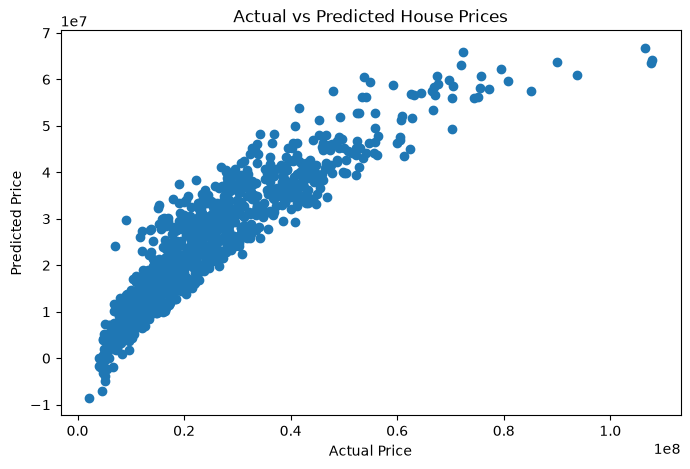

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [22]:
import joblib

# Save trained model
joblib.dump(lr_model, "house_price_model.pkl")

# Save feature columns
joblib.dump(X.columns.tolist(), "house_price_features.pkl")

print("\nModel saved successfully!")


Model saved successfully!


In [23]:
# Test prediction
sample = X_test.iloc[[0]]

predicted_price = lr_model.predict(sample)

print("\nActual Price:", y_test.iloc[0])
print("Predicted Price:", predicted_price[0])


Actual Price: 33511000
Predicted Price: 27545642.15377372


In [24]:
performance = {
    "MAE": mae_lr,
    "RMSE": rmse_lr,
    "R2": r2_lr
} 
joblib.dump(performance, "model_performance.pkl")
print("\nModel performance saved successfully!")




Model performance saved successfully!


In [25]:
actual_predicted = pd.DataFrame({
    "Actual Price": y_test.values, 
    "Predicted Price": y_pred_lr
})
actual_predicted.to_csv("actual_vs_predicted.csv", index=False)
print("\nActual vs Predicted prices saved successfully!")


Actual vs Predicted prices saved successfully!
